In [1]:
!pip install transformers datasets librosa torchaudio accelerate matplotlib

In [2]:
import torch
import numpy as np
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import AutoFeatureExtractor, AutoModelForAudioClassification

from datasets import load_dataset, Audio, DatasetDict

### Φόρτωση συνόλου δεδομένων και speaker independent διαχωρισμός

In [3]:
def load_savee_speaker_independent():
    """
    Συνάρτηση υπεύθυνη για τον speaker independent διαχωρισμό του SAVEE. Το σύνολο
    περιλαμβάνει 4 ομιλητές (DC, JE, JK, KL). Οι ομιλητές DC και JE αντιστοιχίζονται
    στο σύνολο εκπαίδευσης και οι JK και KL στο σύνολο δοκιμής
    """
    dataset = load_dataset("AbstractTTS/SAVEE", split="train")
    dataset = dataset.cast_column("audio", Audio(decode=False))   # για το filter

    def get_speaker(example):
        # Ο κωδικός ομιλητή είναι το πρόθεμα πριν την πρώτη κάτω παύλα, π.χ. "DC_a01.wav" -> "DC"
        return example["file"].split("_")[0]

    train_speakers = ["DC", "JE"]
    test_speakers = ["JK", "KL"]

    train_dataset = dataset.filter(lambda x: get_speaker(x) in train_speakers, load_from_cache_file=False)
    test_dataset = dataset.filter(lambda x: get_speaker(x) in test_speakers, load_from_cache_file=False)

    train_dataset = train_dataset.cast_column("audio", Audio(sampling_rate=16_000))
    test_dataset = test_dataset.cast_column("audio", Audio(sampling_rate=16_000))

    return DatasetDict({"train": train_dataset, "test": test_dataset})

In [4]:
dataset = load_savee_speaker_independent()
print(dataset)

README.md:   0%|          | 0.00/622 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 55.8MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/480 [00:00<?, ? examples/s]

Filter:   0%|          | 0/480 [00:00<?, ? examples/s]

Filter:   0%|          | 0/480 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['file', 'audio', 'gender', 'transcription', 'emotion', 'speaking_rate', 'pitch_mean', 'pitch_std', 'rms', 'relative_db'],
        num_rows: 240
    })
    test: Dataset({
        features: ['file', 'audio', 'gender', 'transcription', 'emotion', 'speaking_rate', 'pitch_mean', 'pitch_std', 'rms', 'relative_db'],
        num_rows: 240
    })
})


In [5]:
#Εξαγωγή των ετικετών των συναισθημάτων σε λίστα
labels = sorted(set(dataset["train"]["emotion"]))
print(labels)

#Δημιουργία λεξικών αντιστοίχισης ετικετών και αριθμών
label2id, id2label = dict(), dict()
for i, label in enumerate(labels):
    label2id[label] = i
    id2label[i] = label

#υπολογισμός αριθμού ετικετών
num_labels = len(labels)
print(f"Διαθέσιμες ετικέτες: {labels}")
print(f"Αριθμός ετικετών: {num_labels}")

['anger', 'disgust', 'fear', 'happiness', 'neutral', 'sadness', 'surprise']
Διαθέσιμες ετικέτες: ['anger', 'disgust', 'fear', 'happiness', 'neutral', 'sadness', 'surprise']
Αριθμός ετικετών: 7


In [6]:
# Φόρτωση του feature extractor του βασικού μοντέλου
model_repo = "facebook/data2vec-audio-base-960h"
feature_extractor = AutoFeatureExtractor.from_pretrained(model_repo)

# Συνάρτηση για την προετοιμασία του dataset
def prepare_dataset(batch):
    audio = batch["audio"]
    #Μετατροπή δείγματος ομιλίας σε κατάλληλη μορφή για το finetuning, με περικοπή στα 6 δευτερόλεπτα
    batch["input_values"] = feature_extractor(
        audio["array"],
        sampling_rate=audio["sampling_rate"],
        max_length=6 * 16000,
        truncation=True,
    ).input_values[0]
    #Μετατροπή της ετικέτας από string σε integer id, για συμβατότητα με τον trainer
    batch["labels"] = label2id[batch["emotion"]]
    return batch

#Εφαρμογή της συνάρτησης σε όλο το dataset και αφαίρεση των υπόλοιπων στηλών
encoded_dataset = dataset.map(prepare_dataset, remove_columns=dataset["train"].column_names, load_from_cache_file=False)

#Εκτύπωση της δομής του νεου dataset
print("Encoded dataset features:")
print(encoded_dataset["train"].features)

#Έλεγχος ότι οι κανονικοποιημένες τιμές είναι καθαρές (χωρίς ακραίες τιμές)
max_abs_vals = [np.max(np.abs(x["input_values"])) for x in encoded_dataset["train"]]
print("\nΜέγιστη απόλυτη τιμή (train):", max(max_abs_vals))

preprocessor_config.json:   0%|          | 0.00/256 [00:00<?, ?B/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

Encoded dataset features:
{'input_values': List(Value('float32')), 'labels': Value('int64')}

Μέγιστη απόλυτη τιμή (train): 12.097386360168457


###Ορισμός μετρικών αξιολόγησης

In [7]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,

    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,

    average_precision_score
)

from sklearn.preprocessing import label_binarize
from scipy.special import softmax

In [8]:
#Λίστα για την αποθήκευση των confusion matrices
all_confusion_matrices = []

"""
Συνάρτηση για τον υπολογισμό των μετρικών ανά εποχή εκπαίδευσης, η οποία προσθέτει
το confusion matrix κάθε εποχής στην all_confusion_matrices. Επειδή γίνεται εκ νέου
υπολογισμός της καλύτερης εποχής μετά το τέλος της εκπαίδευσης, αυτή περιέχει ένα
επιπλέον confusion matrix, ίδιο με το καλύτερο
"""

def compute_metrics(eval_pred):
    logits, labels_true = eval_pred
    predictions = np.argmax(logits, axis=-1)
    probs = softmax(logits, axis=1)

    labels_bin = label_binarize(labels_true, classes=list(range(num_labels)))

    # ROC-AUC (macro-averaged, one-vs-rest)
    try:
        roc_auc = roc_auc_score(labels_bin, probs, multi_class="ovr", average="macro")
    except ValueError:
        roc_auc = float("nan")

    # PR-AUC (macro-averaged average precision)
    try:
        pr_auc = average_precision_score(labels_bin, probs, average="macro")
    except ValueError:
        pr_auc = float("nan")

    accuracy = accuracy_score(labels_true, predictions)
    balanced_accuracy = balanced_accuracy_score(labels_true, predictions)
    precision = precision_score(labels_true, predictions, average="weighted", zero_division=0)
    recall = recall_score(labels_true, predictions, average="weighted", zero_division=0)
    f1 = f1_score(labels_true, predictions, average="weighted", zero_division=0)
    mcc = matthews_corrcoef(labels_true, predictions)
    k_score = cohen_kappa_score(labels_true, predictions)
    logloss = log_loss(labels_true, probs, labels=list(range(num_labels)))

    cm = confusion_matrix(labels_true, predictions, labels=list(range(num_labels)))
    all_confusion_matrices.append(cm)

    return {
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "mcc" : mcc,
        "k_score" : k_score,
        "log_loss": logloss,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc
    }

### Φόρτωση του αρχικού προεκπαιδευμένου μοντέλου

In [9]:
#Φόρτωση του αρχικού μοντελου και εισαγωγή των ετικετών
model = AutoModelForAudioClassification.from_pretrained(model_repo,
    num_labels=num_labels,
    label2id=label2id,
    id2label=id2label,
    ignore_mismatched_sizes=True
)

#Πάγωμα του feature encoder για σταθερότητα κατά την εκπαίδευση
model.freeze_feature_encoder()

#Φόρτωση μοντέλου στην GPU
if torch.cuda.is_available():
    model = model.to('cuda')
print(f"Το μοντέλο φορτώθηκε στη συσκευή: {model.device}")

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  373MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/230 [00:00<?, ?it/s]

[transformers] Data2VecAudioForSequenceClassification LOAD REPORT from: facebook/data2vec-audio-base-960h
Key               | Status     | 
------------------+------------+-
lm_head.bias      | UNEXPECTED | 
lm_head.weight    | UNEXPECTED | 
classifier.bias   | MISSING    | 
projector.bias    | MISSING    | 
projector.weight  | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  373MB            

model.safetensors: downloading bytes:           |  0.00B            

Το μοντέλο φορτώθηκε στη συσκευή: cuda:0


### Ορισμός παραμέτρων εκπαίδευσης

In [10]:
#Δυναμικός υπολογισμός των warmup_steps (10% των συνολικών βημάτων εκπαίδευσης),
#καθώς το SAVEE είναι πολύ μικρό σύνολο και ένα σταθερό warmup 500 βημάτων δεν θα ολοκληρωνόταν ποτέ
per_device_train_batch_size = 8
gradient_accumulation_steps = 4
num_train_epochs = 15

effective_batch_size = per_device_train_batch_size * gradient_accumulation_steps
steps_per_epoch = max(1, len(encoded_dataset["train"]) // effective_batch_size)
total_steps = steps_per_epoch * num_train_epochs
warmup_steps = max(1, int(0.1 * total_steps))

#Καθορισμός μετρικών εκπαίδευσης του μοντέλου
training_args = TrainingArguments(
    output_dir="./data2vec-finetuned-SAVEE",
    per_device_train_batch_size=per_device_train_batch_size,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=gradient_accumulation_steps,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    num_train_epochs=num_train_epochs,
    fp16=False,
    learning_rate=3e-5,
    warmup_steps=warmup_steps,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    push_to_hub=False,
    report_to="none",
)

"""
Data collator για μεταβλητού μήκους δείγματα ήχου.
Το feature_extractor.pad() αναλαμβάνει το padding των input_values ώστε όλα τα
δείγματα ενός batch να έχουν το ίδιο μήκος. Οι ετικέτες έχουν ήδη μετατραπεί σε
integer ids στην prepare_dataset, οπότε εδώ απλώς μετατρέπονται σε tensor
"""

class DataCollatorCTCWithPadding:
    def __init__(self, feature_extractor, padding=True):
        self.feature_extractor = feature_extractor
        self.padding = padding

    def __call__(self, features):
        input_features = [{"input_values": feature["input_values"]} for feature in features]
        batch = self.feature_extractor.pad(
            input_features,
            padding=self.padding,
            return_tensors="pt",
        )
        #Μετατροπή των integer labels σε tensor
        batch["labels"] = torch.tensor([feature["labels"] for feature in features], dtype=torch.long)
        return batch

data_collator = DataCollatorCTCWithPadding(feature_extractor=feature_extractor, padding=True)

In [11]:
#Καθαρισμός των confusion matrix, από τυχόν προηγούμενες εκτελέσεις
all_confusion_matrices.clear()

### Δημιουργία και Εκπαίδευση του Trainer

In [12]:
#Κλήση του trainer και εισαγωγή των παραμέτρων εκπαίδευσης
#Χρησιμοποιείται early stopping με υπομονή 3 εποχών βάσει του eval_loss
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=encoded_dataset["train"],
    eval_dataset=encoded_dataset["test"],
    compute_metrics=compute_metrics,
    data_collator=data_collator,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

print("Εκκίνηση εκπαίδευσης...")
trainer.train()
print("Εκπαίδευση ολοκληρώθηκε!")

Εκκίνηση εκπαίδευσης...


Epoch,Training Loss,Validation Loss,Accuracy,Balanced Accuracy,Precision,Recall,F1,Mcc,K Score,Log Loss,Roc Auc,Pr Auc,Runtime,Samples Per Second,Steps Per Second
1,7.260046,1.930977,0.250000,0.142857,0.062500,0.250000,0.100000,0.000000,0.000000,1.930977,0.541638,0.169439,14.182500,16.922000,2.115000
2,7.222355,1.915848,0.250000,0.142857,0.062500,0.250000,0.100000,0.000000,0.000000,1.915848,0.637857,0.255644,13.977500,17.170000,2.146000
3,7.171213,1.902155,0.250000,0.142857,0.062500,0.250000,0.100000,0.000000,0.000000,1.902155,0.684106,0.310712,15.408200,15.576000,1.947000
4,7.111436,1.885502,0.250000,0.142857,0.062500,0.250000,0.100000,0.000000,0.000000,1.885502,0.706512,0.347057,14.790800,16.226000,2.028000
5,6.988478,1.848809,0.287500,0.185714,0.118037,0.287500,0.150756,0.129395,0.064935,1.848809,0.729452,0.376905,15.489500,15.494000,1.937000
6,6.799847,1.779296,0.345833,0.257143,0.133615,0.345833,0.192070,0.229583,0.182824,1.779296,0.737103,0.394568,15.450200,15.534000,1.942000
7,6.597882,1.721903,0.358333,0.271429,0.285023,0.358333,0.222609,0.272761,0.216285,1.721903,0.742865,0.420425,15.297500,15.689000,1.961000
8,6.331454,1.669321,0.370833,0.283333,0.291407,0.370833,0.230254,0.294131,0.232529,1.669321,0.757351,0.429256,14.888200,16.120000,2.015000
9,6.199934,1.633068,0.375000,0.288095,0.298092,0.375000,0.243062,0.300640,0.240025,1.633068,0.755355,0.417560,14.888800,16.120000,2.015000
10,6.056476,1.615358,0.391667,0.307143,0.304734,0.391667,0.274596,0.320970,0.262160,1.615359,0.763709,0.427025,15.054300,15.942000,1.993000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Εκπαίδευση ολοκληρώθηκε!


In [13]:
#Εκτύπωση των τελικών αποτελεσμάτων της εκπαίδευσης
eval_results = trainer.evaluate()
print(f"Αποτελέσματα αξιολόγησης: {eval_results}")

Training Loss,Validation Loss,Epoch,Accuracy,Balanced Accuracy,Precision,Recall,F1,Mcc,K Score,Log Loss,Roc Auc,Pr Auc,Runtime,Samples Per Second,Steps Per Second
5.840899,1.594464,15,0.370833,0.280952,0.216604,0.370833,0.251552,0.273414,0.233989,1.594464,0.747904,0.397573,14.688500,16.339000,2.042000


Αποτελέσματα αξιολόγησης: {'eval_loss': 1.59446382522583, 'eval_accuracy': 0.37083333333333335, 'eval_balanced_accuracy': 0.28095238095238095, 'eval_precision': 0.21660395472352548, 'eval_recall': 0.37083333333333335, 'eval_f1': 0.2515517413883604, 'eval_mcc': 0.27341435699995165, 'eval_k_score': 0.23398858592263794, 'eval_log_loss': 1.5944637907193155, 'eval_roc_auc': 0.7479043839758125, 'eval_pr_auc': 0.39757265619761767, 'eval_runtime': 14.6885, 'eval_samples_per_second': 16.339, 'eval_steps_per_second': 2.042}


### Οπτικοποίηση αποτελεσμάτων (Confusion Matrices)

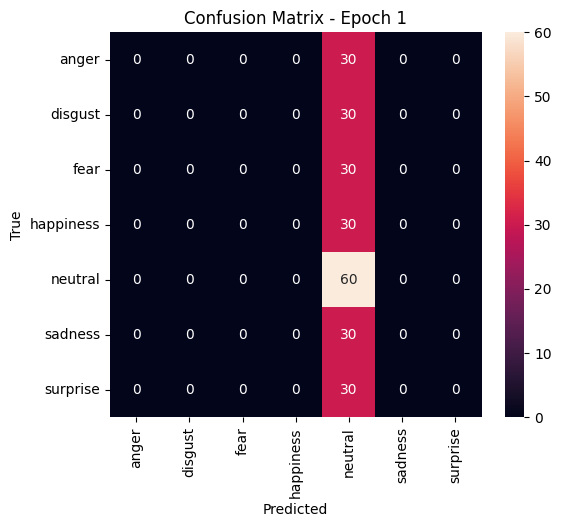

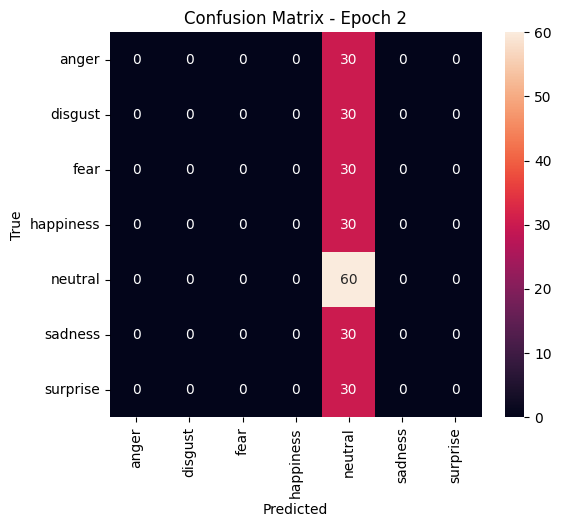

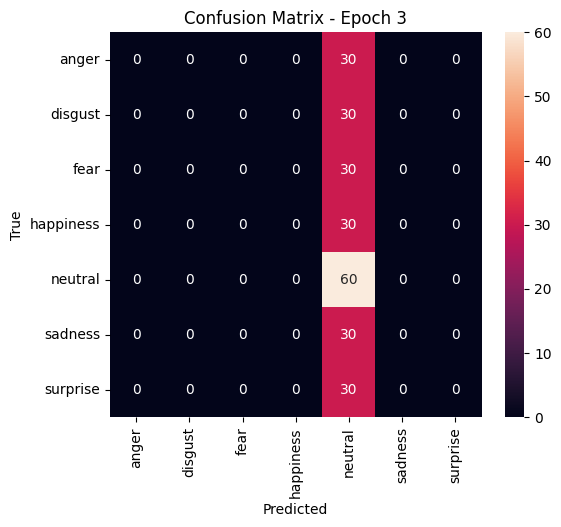

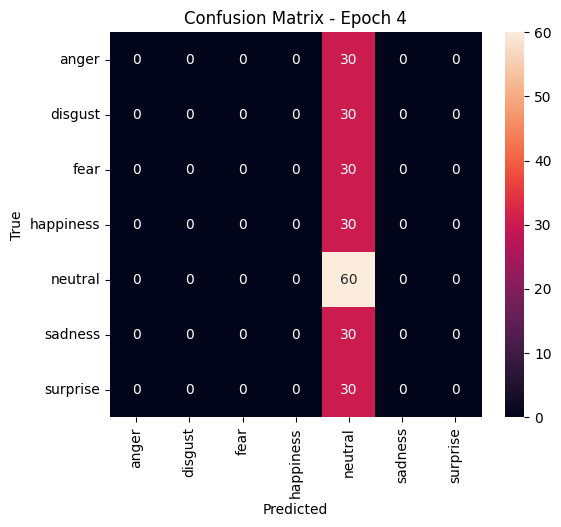

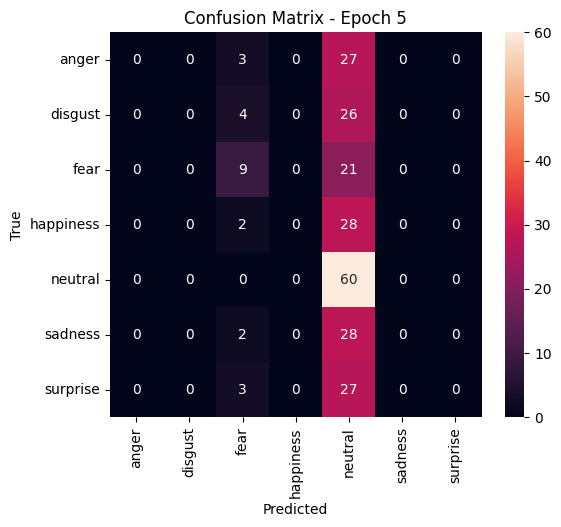

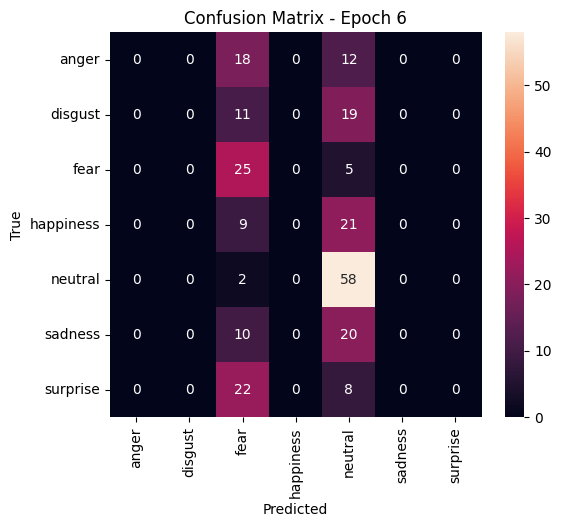

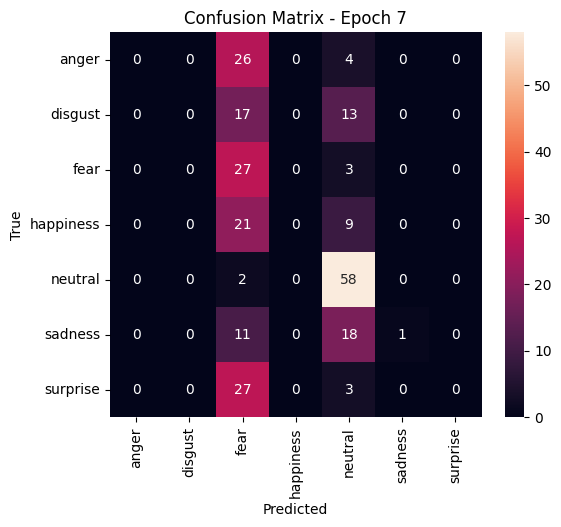

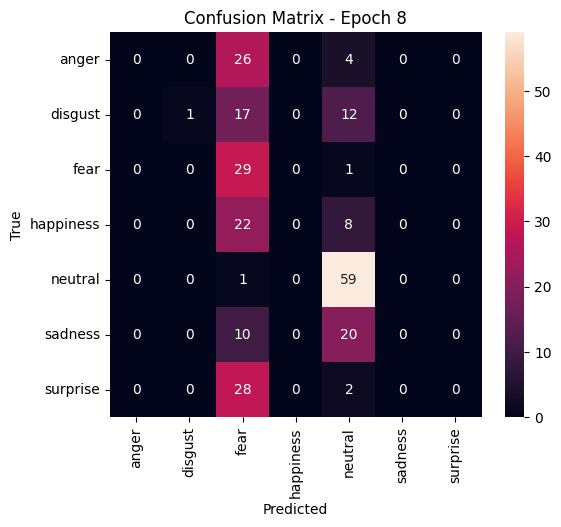

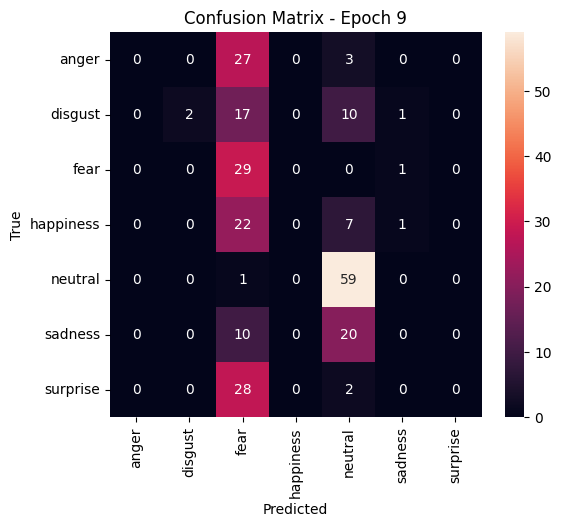

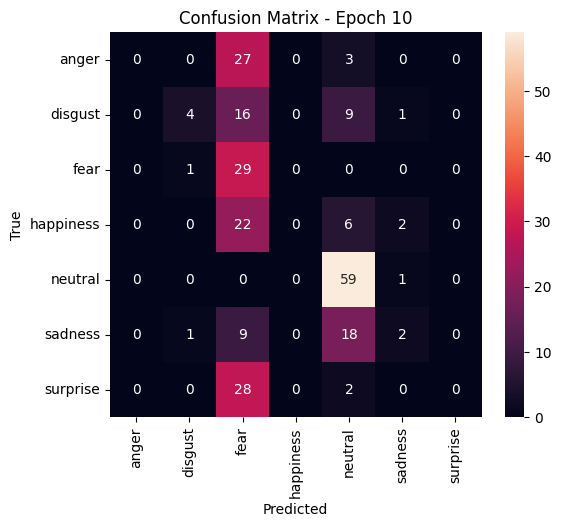

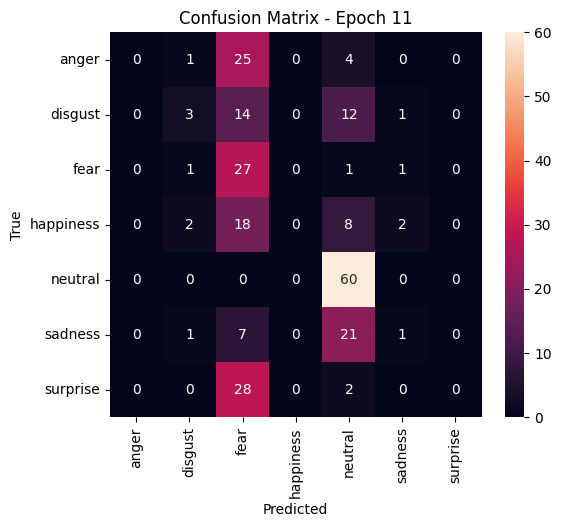

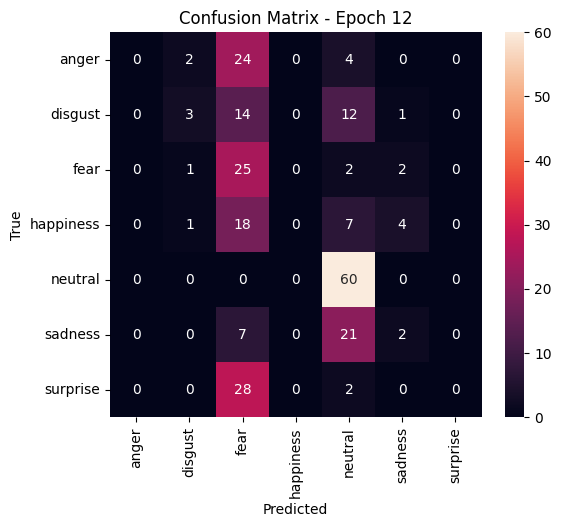

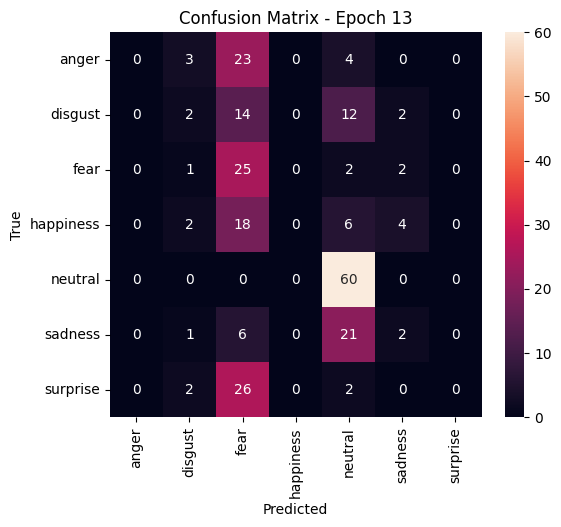

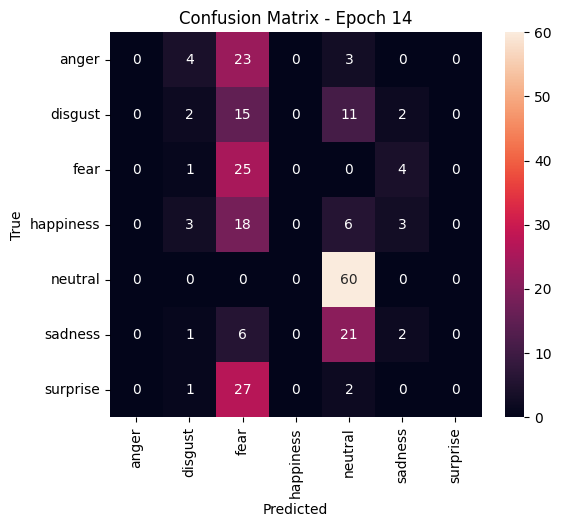

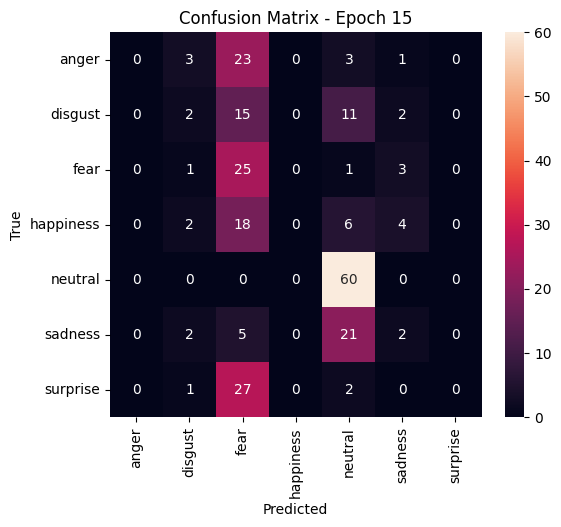

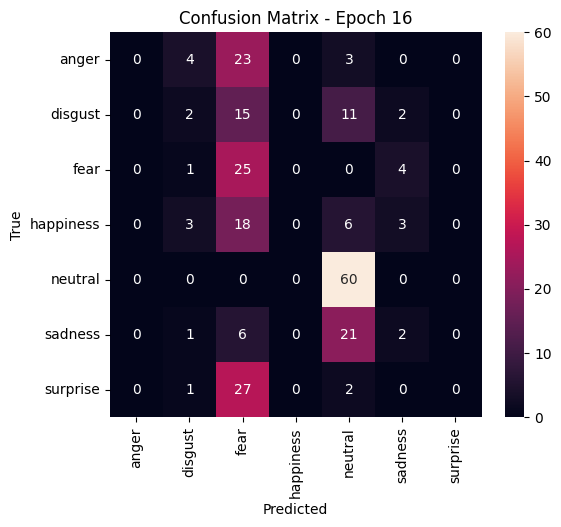

In [14]:
#Αποθήκευση των ετικετών για τους άξονες των matrices
labels = [
    model.config.id2label[i]
    for i in sorted(model.config.id2label.keys())
]

#Loop στην λίστα με τα confusion matrices
for epoch, cm in enumerate(all_confusion_matrices):
  #Δημιουργία γραφήματος
  plt.figure(figsize=(6,5))

  #Δημιουργία Heatmap
  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      xticklabels=labels,
      yticklabels=labels
  )

  plt.title(f"Confusion Matrix - Epoch {epoch+1}")
  plt.xlabel("Predicted")
  plt.ylabel("True")
  plt.show()

### Αποθήκευση εκπαιδευμένου μοντέλου στο HuggingFace Hub

In [15]:
from google.colab import userdata
from huggingface_hub import login

login(token=userdata.get('HF_TOKEN'))

In [16]:
repo_id = "VasilisAsim/data2vec-finetuned-SAVEE"

#Αποθήκευση του μοντέλου στο HuggingFace
model.push_to_hub(repo_id)

#Αποθήκευση του Feature Extractor
feature_extractor.push_to_hub(repo_id)

print(f"Το μοντέλο και ο επεξεργαστής αποθηκεύτηκαν στο Hugging Face Hub με ID: {repo_id}")

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ..._qntawf/model.safetensors:   0%|          |  550kB /  373MB            

No files have been modified since last commit. Skipping to prevent empty commit.


Το μοντέλο και ο επεξεργαστής αποθηκεύτηκαν στο Hugging Face Hub με ID: VasilisAsim/data2vec-finetuned-SAVEE
